Imports

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
import re

In [8]:
from textblob import TextBlob

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from scipy import sparse
from sklearn.preprocessing import StandardScaler

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import classification_report

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier

Loading Dataset

In [13]:
train = pd.read_csv(r"D:\projects\toxic_comment_classification\jigsaw-toxic-comment-classification-challenge\train.csv\train.csv")
print(train.shape)
train.head()

(159571, 8)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [14]:
# Checkking for nulls in dataset
print(train.isnull().sum())

id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


In [15]:
label_cols = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

# Total comments
print(f"Total comments: {train.shape[0]}")

# Count per label
for col in label_cols:
    print(f"{col}: {train[col].sum()}")

# Multi-label comments
train['num_labels'] = train[label_cols].sum(axis=1)
multi_label_count = (train['num_labels'] > 1).sum()
print(f"Multi-label comments: {multi_label_count}")

Total comments: 159571
toxic: 15294
severe_toxic: 1595
obscene: 8449
threat: 478
insult: 7877
identity_hate: 1405
Multi-label comments: 9865


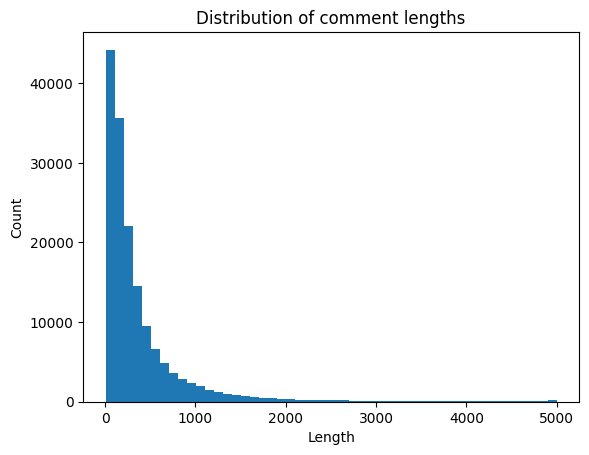

In [16]:
# Length of comments
train['comment_length'] = train['comment_text'].apply(len)

plt.hist(train['comment_length'], bins=50)
plt.title("Distribution of comment lengths")
plt.xlabel("Length")
plt.ylabel("Count")
plt.show()

Text Preprocessing

In [17]:
def clean_text(text):
    # Lowercase
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r"http\S+|www.\S+", "", text)
    
    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)
    
    # Remove special characters and digits (keep only alphabets and spaces)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    
    # Remove extra whitespaces
    text = re.sub(r"\s+", " ", text).strip()
    
    return text

In [18]:
train['clean_comment'] = train['comment_text'].apply(clean_text)

In [19]:
# sample before and after cleaning
train[['comment_text', 'clean_comment']].head(5)

,comment_text,clean_comment
0,Explanation\nWhy the edits made under my usern...,explanation why the edits made under my userna...
1,D'aww! He matches this background colour I'm s...,daww he matches this background colour im seem...
2,"Hey man, I'm really not trying to edit war. It...",hey man im really not trying to edit war its j...
3,"""\nMore\nI can't make any real suggestions on ...",more i cant make any real suggestions on impro...
4,"You, sir, are my hero. Any chance you remember...",you sir are my hero any chance you remember wh...


Feature Engineering

In [20]:
# Number of characters
train['num_chars'] = train['clean_comment'].apply(len)

In [21]:
# Number of words
train['num_words'] = train['clean_comment'].apply(lambda x: len(x.split()))

In [22]:
# Punctuation & Uppercase Features
train['num_exclaims'] = train['comment_text'].apply(lambda x: x.count('!')) # Number of exclamation marks
train['num_questions'] = train['comment_text'].apply(lambda x: x.count('?')) # Number of question marks
train['num_uppercase_words'] = train['comment_text'].apply(lambda x: sum(1 for u in x.split() if u.isupper())) # Number of uppercase words
# These can indicate aggression or emphasis, often correlated with toxic speech

In [23]:
# Sentiment Score Feature
def get_sentiment(text):
    return TextBlob(text).sentiment.polarity

train['sentiment'] = train['clean_comment'].apply(get_sentiment)

In [24]:
bad_words = [
    'fuck', 'shit', 'bitch', 'asshole', 'bastard', 'faggot', 'nigga', 'nigger', 'cunt', 'slut', 'dick', 'cock', 'whore',
    'piss', 'douche', 'bollocks', 'bugger', 'bollock', 'bloody', 'damn', 'hell', 'motherfucker', 'crap',
    'twat', 'wanker', 'prick', 'arse', 'git', 'tit', 'slag', 'tosser', 'cocksucker', 'dildo', 'fag', 'skank', 'cum',
    'spaz', 'retard', 'dyke', 'homo', 'queer', 'rapist', 'molester'
]


In [25]:
def save_bad_words_to_file(bad_words, filename="bad_words.txt"):
    with open(filename, "w") as f:
        for word in bad_words:
            f.write(f"{word}\n")
    print(f"Saved {len(bad_words)} bad words to {filename}")

# Call the function
save_bad_words_to_file(bad_words)

Saved 43 bad words to bad_words.txt


In [26]:
def load_bad_words_from_file(filename="bad_words.txt"):
    with open(filename, "r") as f:
        bad_words = [line.strip() for line in f]
    return bad_words

# Usage
bad_words = load_bad_words_from_file()
print(f"Loaded {len(bad_words)} bad words from file.")

Loaded 43 bad words from file.


In [27]:
def count_bad_words(text, bad_words):
    words = text.split()
    return sum(1 for w in words if w in bad_words)

train['num_bad_words'] = train['clean_comment'].apply(lambda x: count_bad_words(x, bad_words))

In [28]:
train[['clean_comment', 'num_chars', 'num_words', 'num_exclaims', 'num_questions', 'num_uppercase_words', 'sentiment', 'num_bad_words']].head(5)

,clean_comment,num_chars,num_words,num_exclaims,num_questions,num_uppercase_words,sentiment,num_bad_words
0,explanation why the edits made under my userna...,245,43,0,1,2,0.136364,0
1,daww he matches this background colour im seem...,86,14,1,0,1,0.200000,0
2,hey man im really not trying to edit war its j...,227,42,0,0,0,0.160000,0
3,more i cant make any real suggestions on impro...,594,109,0,0,5,0.200000,0
4,you sir are my hero any chance you remember wh...,62,13,0,1,0,0.000000,0


Baseline Modeling with TF-IDF + Engineered Features

- Preparing feature matrix

In [31]:
# TF-IDF Vectorization
# Initialize vectorizer
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))

# Fit transform on clean comments
X_tfidf = tfidf.fit_transform(train['clean_comment'])

In [32]:
engineered_cols = ['num_chars', 'num_words', 'num_exclaims', 'num_questions', 'num_uppercase_words', 'sentiment', 'num_bad_words']
X_engineered = train[engineered_cols].reset_index(drop=True)

In [33]:
# Combining TF-IDF and Engineered Features
# Converting engineered features to sparse matrix
X_engineered_sparse = sparse.csr_matrix(X_engineered.values)

# Combine
X_final = hstack([X_tfidf, X_engineered_sparse])

In [34]:
# Target Labels > for multi-label classification
y = train[['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']].values

In [35]:
X_train, X_val, y_train, y_val = train_test_split(X_final, y, test_size=0.2, random_state=42)

Building Baseline Models

In [30]:
# Initializing model
clf = OneVsRestClassifier(LogisticRegression(max_iter=1000, class_weight='balanced'))

# Fitting model
clf.fit(X_train, y_train)

# Predicting on validation set
y_pred = clf.predict(X_val)

# Evaluation
print(classification_report(y_val, y_pred, target_names=['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']))

D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver op

               precision    recall  f1-score   support

        toxic       0.47      0.87      0.61      3056
 severe_toxic       0.21      0.89      0.34       321
      obscene       0.50      0.90      0.64      1715
       threat       0.08      0.84      0.15        74
       insult       0.37      0.88      0.52      1614
identity_hate       0.12      0.83      0.21       294

    micro avg       0.37      0.88      0.52      7074
    macro avg       0.29      0.87      0.41      7074
 weighted avg       0.42      0.88      0.56      7074
  samples avg       0.05      0.08      0.06      7074



D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
D:\projects\toxic_comment_classification\toxic_comment_classification_env

In [36]:
# Scaling engineered features
scaler = StandardScaler(with_mean=False)
X_engineered_scaled = scaler.fit_transform(X_engineered)

# Converting to sparse
X_engineered_sparse = sparse.csr_matrix(X_engineered_scaled)

# Combining with TF-IDF
X_final = hstack([X_tfidf, X_engineered_sparse])

In [37]:
X_train, X_val, y_train, y_val = train_test_split(X_final, y, test_size=0.2, random_state=42)

In [33]:
# Initializing model with increased max_iter and optional 'saga' solver for sparse data
clf = OneVsRestClassifier(LogisticRegression(max_iter=2000, solver='saga', class_weight='balanced'))

# Fitting model
clf.fit(X_train, y_train)

# Predicting on validation set
y_pred = clf.predict(X_val)

# Evaluation
print(classification_report(y_val, y_pred, target_names=['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']))

D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\

               precision    recall  f1-score   support

        toxic       0.54      0.86      0.66      3056
 severe_toxic       0.20      0.90      0.33       321
      obscene       0.53      0.89      0.66      1715
       threat       0.07      0.88      0.14        74
       insult       0.41      0.87      0.56      1614
identity_hate       0.12      0.82      0.21       294

    micro avg       0.40      0.87      0.55      7074
    macro avg       0.31      0.87      0.43      7074
 weighted avg       0.47      0.87      0.60      7074
  samples avg       0.05      0.08      0.06      7074



D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Random Forest Baseline

In [34]:
# Initializing Random Forest
rf_clf = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, class_weight='balanced', n_jobs=-1, random_state=42))
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_val)
print(classification_report(y_val, y_pred_rf, target_names=['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']))

               precision    recall  f1-score   support

        toxic       0.91      0.52      0.66      3056
 severe_toxic       0.59      0.17      0.27       321
      obscene       0.90      0.56      0.69      1715
       threat       0.50      0.05      0.10        74
       insult       0.82      0.43      0.56      1614
identity_hate       0.76      0.06      0.12       294

    micro avg       0.88      0.47      0.61      7074
    macro avg       0.75      0.30      0.40      7074
 weighted avg       0.86      0.47      0.60      7074
  samples avg       0.05      0.04      0.04      7074



D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


BERT Fine-Tuning Plan for Toxic Comment Multi-Label Classification

In [44]:
from transformers import BertTokenizerFast

In [45]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizerFast, BertForSequenceClassification, AdamW, get_linear_schedule_with_warmup
from tqdm import tqdm

In [46]:
tokenizer = BertTokenizerFast.from_pretrained('bert-base-uncased')

def tokenize_function(examples):
    return tokenizer(
        examples['clean_comment'],
        padding='max_length',
        truncation=True,
        max_length=128
    )

In [47]:
class ToxicCommentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer_name='bert-base-uncased', max_len=128):
        """
        texts: list/pandas Series of comments
        labels: numpy array/ list of multi-label targets
        """
        self.texts = texts
        self.labels = labels
        self.tokenizer = BertTokenizerFast.from_pretrained(tokenizer_name)
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        labels = torch.tensor(self.labels[idx], dtype=torch.float)

        # Tokenize text
        encoding = self.tokenizer.encode_plus(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            truncation=True,
            padding='max_length',
            return_attention_mask=True,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].flatten(),  # Flatten from (1, max_len) to (max_len,)
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': labels
        }

In [48]:
train_dataset = ToxicCommentDataset(
    texts = train['clean_comment'].tolist(),
    labels = train[['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']].values,
    max_len = 128
)


D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\huggingface_hub\file_download.py:943: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [49]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

# Test iteration
batch = next(iter(train_loader))
print(batch['input_ids'].shape)       # (batch_size, max_len)
print(batch['attention_mask'].shape)  # (batch_size, max_len)
print(batch['labels'].shape)          # (batch_size, num_labels)

torch.Size([16, 128])
torch.Size([16, 128])
torch.Size([16, 6])


In [50]:
model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=6,
    problem_type='multi_label_classification'
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.weight', 'classifier.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [51]:
optimizer = AdamW(model.parameters(), lr=2e-5)

epochs = 3
total_steps = len(train_loader) * epochs

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps = 0,
    num_training_steps = total_steps
)

D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\transformers\optimization.py:411: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


In [52]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [64]:
model.train()
for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")
    for batch in tqdm(train_loader):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )
        loss = outputs.loss

        loss.backward()
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()

    print(f"Loss after epoch {epoch+1}: {loss.item():.4f}")

Epoch 1/3


  1%|▋                                                                            | 82/9974 [13:27<27:03:04,  9.84s/it]


KeyboardInterrupt: 

Training on subset of data

In [53]:
train_subset = train.sample(1000, random_state=42)

train_dataset = ToxicCommentDataset(
    texts = train_subset['clean_comment'].tolist(),
    labels = train_subset[['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']].values,
    max_len = 128
)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=0)

D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\huggingface_hub\file_download.py:943: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [54]:
accumulation_steps = 2
model.train()

for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")
    optimizer.zero_grad()
    
    for step, batch in enumerate(tqdm(train_loader)):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )
        loss = outputs.loss
        loss = loss / accumulation_steps  # Scale loss

        loss.backward()

        if (step + 1) % accumulation_steps == 0:
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()

    print(f"Loss after epoch {epoch+1}: {loss.item():.4f}")

Epoch 1/3


100%|██████████████████████████████████████████████████████████████████████████████████| 63/63 [11:04<00:00, 10.55s/it]


Loss after epoch 1: 0.1584
Epoch 2/3


100%|██████████████████████████████████████████████████████████████████████████████████| 63/63 [10:54<00:00, 10.39s/it]


Loss after epoch 2: 0.0505
Epoch 3/3


100%|██████████████████████████████████████████████████████████████████████████████████| 63/63 [11:01<00:00, 10.50s/it]

Loss after epoch 3: 0.0304


In [55]:
model.eval()
all_labels = []
all_preds = []

with torch.no_grad():
    for batch in tqdm(train_loader):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].cpu().numpy()
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        logits = outputs.logits
        probs = torch.sigmoid(logits).cpu().numpy()
        
        all_labels.append(labels)
        all_preds.append(probs)

# Concatenating all batches
all_labels = np.vstack(all_labels)
all_preds = np.vstack(all_preds)

# Converting probabilities to binary predictions (threshold=0.5)
all_preds_binary = (all_preds >= 0.5).astype(int)

# classification report
print(classification_report(all_labels, all_preds_binary, target_names=['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']))

100%|██████████████████████████████████████████████████████████████████████████████████| 63/63 [03:41<00:00,  3.51s/it]

               precision    recall  f1-score   support

        toxic       1.00      0.40      0.57        98
 severe_toxic       0.00      0.00      0.00         7
      obscene       0.00      0.00      0.00        51
       threat       0.00      0.00      0.00         3
       insult       1.00      0.08      0.15        50
identity_hate       0.00      0.00      0.00         8

    micro avg       1.00      0.20      0.33       217
    macro avg       0.33      0.08      0.12       217
 weighted avg       0.68      0.20      0.29       217
  samples avg       0.04      0.02      0.02       217




D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
D:\projects\toxic_comment_classification\toxic_comment_classification_env\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parame

Saving trained model

In [56]:
model.save_pretrained('bert_toxic_model/')
tokenizer.save_pretrained('bert_toxic_model/')

('bert_toxic_model/tokenizer_config.json',
 'bert_toxic_model/special_tokens_map.json',
 'bert_toxic_model/vocab.txt',
 'bert_toxic_model/added_tokens.json',
 'bert_toxic_model/tokenizer.json')

Quantization

In [57]:
# Loading trained model
model = BertForSequenceClassification.from_pretrained('bert_toxic_model/')
model.eval()

# Applying dynamic quantization to Linear layers
quantized_model = torch.quantization.quantize_dynamic(
    model,
    {torch.nn.Linear},
    dtype=torch.qint8
)

# Save quantized model
torch.save(quantized_model.state_dict(), 'bert_toxic_model_quantized.pt')

In [59]:
import time
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [62]:
# Sample input text
text = "You are such an idiot and your work is pathetic."

# Loading tokenizer
tokenizer = BertTokenizerFast.from_pretrained('bert_toxic_model/')
inputs = tokenizer(text, return_tensors='pt', padding=True, truncation=True, max_length=128)

# 1. Original model inference

model_original = BertForSequenceClassification.from_pretrained('bert_toxic_model/').to(device)
model_original.eval()

start_time = time.time()
with torch.no_grad():
    outputs_original = model_original(
        input_ids=inputs['input_ids'].to(device),
        attention_mask=inputs['attention_mask'].to(device)
    )
end_time = time.time()

print(" Original Model Prediction:", torch.sigmoid(outputs_original.logits))
print(f" Original model inference time: {end_time - start_time:.4f} seconds")

# 2. Quantized model inference
model_for_quant = BertForSequenceClassification.from_pretrained('bert_toxic_model/')

# Applying dynamic quantization to Linear layers
quantized_model = torch.quantization.quantize_dynamic(
    model_for_quant,
    {torch.nn.Linear},
    dtype=torch.qint8
).to(device)
quantized_model.eval()

start_time = time.time()
with torch.no_grad():
    outputs_quantized = quantized_model(
        input_ids=inputs['input_ids'].to(device),
        attention_mask=inputs['attention_mask'].to(device)
    )
end_time = time.time()

print(" Quantized Model Prediction:", torch.sigmoid(outputs_quantized.logits))
print(f" Quantized model inference time: {end_time - start_time:.4f} seconds")

 Original Model Prediction: tensor([[0.5622, 0.2791, 0.3215, 0.3060, 0.3991, 0.3009]])
 Original model inference time: 0.0455 seconds
 Quantized Model Prediction: tensor([[0.5000, 0.2320, 0.2575, 0.2305, 0.3327, 0.2203]])
 Quantized model inference time: 0.0235 seconds


In [2]:
from lime.lime_text import LimeTextExplainer

# Load tokenizer and quantized model
tokenizer = BertTokenizer.from_pretrained('bert_toxic_model/')
model = BertForSequenceClassification.from_pretrained('bert_toxic_model/')
model.load_state_dict(torch.load('bert_toxic_model_quantized.pt'))
model.eval()

# Define class names
class_names = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

# Define prediction function for LIME
def predict_proba(texts):
    inputs = tokenizer(
        texts,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=128
    )
    with torch.no_grad():
        outputs = model(
            input_ids=inputs['input_ids'],
            attention_mask=inputs['attention_mask']
        )
        probs = torch.sigmoid(outputs.logits).cpu().numpy()
    return probs

# Create explainer
explainer = LimeTextExplainer(class_names=class_names)

# Choose a sample comment to explain
sample_comment = "You are such a pathetic idiot. No one likes you."

# Generate explanation
exp = explainer.explain_instance(
    sample_comment,
    predict_proba,
    num_features=10
)

# Display explanation
exp.show_in_notebook(text=True)

ModuleNotFoundError: No module named 'lime'